[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MuhammadErlanggaKurniawan/ets-ml2-kelompok/blob/main/notebooks/ETS_ML2_Kesegaran_Ayam.ipynb)

# Klasifikasi Kesegaran Daging Ayam Berbasis Ensemble dan Reinforcement Learning
### Proyek ETS Machine Learning II

**Kelompok:** Muhammad Erlangga Kurniawan (23083010045) · Michael Valencio Erasmo Bagas Ganendra (23083010042) ·
Rijal Apuila Khufi (23083010033)

---

## Ringkasan proyek

Daging ayam yang mulai busuk mengeluarkan gas, misalnya amonia dan senyawa organik yang mudah menguap.
Sensor gas murah seri **MQ** dapat mendeteksi gas tersebut. Rangkaian beberapa sensor gas seperti ini disebut
**electronic nose (e-nose)**.

**Pertanyaan proyek:** dari bacaan sensor saja, dapatkah model *machine learning* mengklasifikasikan daging ayam sebagai masih
**Fresh**, **Semi-fresh**, atau sudah **Spoiled**?

**Data:** satu dataset publik, *e-nose* daging ayam dari Anwar & Anwar (2025). Isinya 7 sensor
(6 sensor gas MQ + kelembapan), 15 sesi rekaman, sekitar 218 ribu bacaan.

**Kenapa topik ini:** ini irisan skripsi kami bertiga.
- Erlangga: kesegaran makanan (termasuk ayam) dengan sensor **MQ-135**. Sensor yang sama ada di dataset ini.
- Rijal: mutu produk unggas (kuning telur puyuh).
- Michael: model *gradient boosting* (XGBoost), dipakai di bagian ensemble.

**Tiga teknik Machine Learning II yang dipakai** (minimal 3 aspek → nilai minimum kelompok 75):
1. **Augmentasi data**
2. **Ensemble learning**
3. **Reinforcement learning**

## Peta notebook

| Bagian | Isi | Rubrik dosen |
|---|---|---|
| 1 | Persiapan | — |
| 2 | **Akuisisi** data | pipeline: akuisisi |
| 3 | Kenali datanya | latar belakang |
| 4 | Membuat label Fresh / Semi-fresh / Spoiled | pengolahan |
| 5 | **Pengolahan data (wrangling)** | wrangling (15%) |
| 6 | Skema validasi dan pencegahan *data leakage* | analisis (25%) |
| 7 | **Ensemble learning** | ensemble (15%) |
| 8 | **Augmentasi data** | augmentasi (15%) |
| 9 | **Reinforcement learning** + efek tambah data | reinforcement (15%) |
| 10 | Sensor mana yang paling penting | analisis |
| 11 | **Ringkasan semua angka** + kesimpulan | presentasi (30%) |

## Cara menjalankan
Pilih menu **Runtime → Run all**. Tidak perlu GPU. Waktunya sekitar 10 menit di Colab (sekitar 1 menit di laptop).
Semua grafik dan angka disimpan di folder `hasil/`.
Setiap bagian diakhiri kotak **📌 Hasil**, yang angkanya ditulis otomatis dari hasil run.

---
# Bagian 1 — Persiapan
Memuat *library*. Semua sudah tersedia di Google Colab.

In [1]:
import hashlib, importlib.metadata, json, subprocess, sys, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# same XGBoost version as the run behind the slides, so XGBoost and Voting give the same numbers everywhere
XGB_VERSION = "3.4.1"
try:
    installed = importlib.metadata.version("xgboost")
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != XGB_VERSION:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"xgboost=={XGB_VERSION}"])
    except subprocess.CalledProcessError:
        print(f"Gagal memasang xgboost {XGB_VERSION}; memakai versi {installed}. Angka XGBoost bisa sedikit beda.")
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
OUT = Path("hasil")
OUT.mkdir(exist_ok=True)
CLASSES = ["Fresh", "Semi-fresh", "Spoiled"]
CLASS_COLORS = ["#13866B", "#E3A33B", "#C4553B"]
TEAL, GREY, AMBER, RED, INK = "#0F5257", "#9AA5A6", "#E3A33B", "#C4553B", "#16262B"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})
RESULTS = {}  # every number used in the summary and the slides


def fmt(x, n=3):
    return f"{x:.{n}f}".replace(".", ",")


def pct(x):
    return f"{100 * x:.1f}%".replace(".", ",")


def num(n):
    return f"{n:,}".replace(",", ".")


def signed(x):
    return f"{x:+.3f}".replace(".", ",")


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")


def result_box(text):
    display(Markdown("> **📌 Hasil**\n>\n" + "\n".join("> " + line for line in text.strip().split("\n"))))


print("Siap.")

Siap.


---
# Bagian 2 — Akuisisi data

**Sumber:** Anwar, H., & Anwar, T. (2025). *Quality assessment of chicken using machine learning and electronic
nose.* Sensing and Bio-Sensing Research, 47, 100739. Data dan kode penulis ada di GitHub
`talhaanwarch/chicken_assessment_e-nose`.

**Apa yang dilakukan:** mengunduh file `complete_data.csv` (±12 MB), lalu mengecek "sidik jari" file (SHA-256).
Kalau isi file berubah satu angka saja, sidik jarinya ikut berubah. Jadi kita yakin data yang dipakai sama persis
dengan milik penulis.

In [2]:
URL = ("https://raw.githubusercontent.com/talhaanwarch/chicken_assessment_e-nose/"
       "e7e3ca686bce0ef3e5c59f9833c85a3190c36e6e/complete_data.csv")
SHA256 = "7c9920fcfe523af1ee2855d53f13334ddba93db5135d7868b9f63c5cd488d953"
path = Path("data/raw/complete_data.csv")
if not path.exists():
    path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, path)
assert hashlib.sha256(path.read_bytes()).hexdigest() == SHA256, "Isi file berbeda dari sumber asli"

# column order follows the author's notebook: s1..s6 are MQ sensors, s8 is humidity
SENSOR_NAMES = {"s1": "MQ-135", "s2": "MQ-2", "s3": "MQ-3", "s4": "MQ-6", "s5": "MQ-7", "s6": "MQ-9",
                "s8": "Kelembapan"}
raw = pd.read_csv(path).rename(columns={**SENSOR_NAMES, "hour": "jam", "group": "sesi"})
MQ = ["MQ-135", "MQ-2", "MQ-3", "MQ-6", "MQ-7", "MQ-9"]
SENSORS = MQ + ["Kelembapan"]
print(f"Data terunduh dan terverifikasi: {num(len(raw))} bacaan, {raw.sesi.nunique()} sesi.")
display(raw.head())

Data terunduh dan terverifikasi: 218.318 bacaan, 15 sesi.


,MQ-135,MQ-2,MQ-3,MQ-6,MQ-7,MQ-9,Kelembapan,jam,sesi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
1,2.0,4.0,3.0,1.0,1.0,0.0,0.1,0,0
2,4.0,6.0,-5.0,0.0,1.0,-1.0,0.1,0,0
3,7.0,10.0,4.0,3.0,1.0,7.0,0.0,0,0
4,13.0,13.0,8.0,7.0,2.0,19.0,0.0,0,0


---
# Bagian 3 — Kenali datanya

- Setiap **sesi** adalah satu rekaman: sampel ayam diletakkan di dalam kotak sensor, lalu dipantau terus selama
  12–27 jam.
- Sensor membaca sekitar 11–12 kali per menit. Kolom `jam` berisi sudah berapa jam ayam dipantau.
- Nilai sensor sudah dikurangi nilai awalnya, jadi setiap sesi mulai dari 0.

Grafik di bawah menunjukkan bacaan MQ-135 untuk setiap sesi.

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
sesi,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0
bacaan,19142.0,17223.0,19233.0,17336.0,17282.0,17221.0,17856.0,17303.0,15535.0,8581.0,10788.0,12678.0,8670.0,9829.0,9641.0
lama_jam,27.0,24.0,26.0,24.0,24.0,24.0,25.0,24.0,22.0,12.0,15.0,18.0,12.0,14.0,13.0
puncak_MQ135,315.0,119.0,419.0,412.0,526.0,544.0,535.0,602.0,657.0,206.0,534.0,677.0,593.0,620.0,603.0


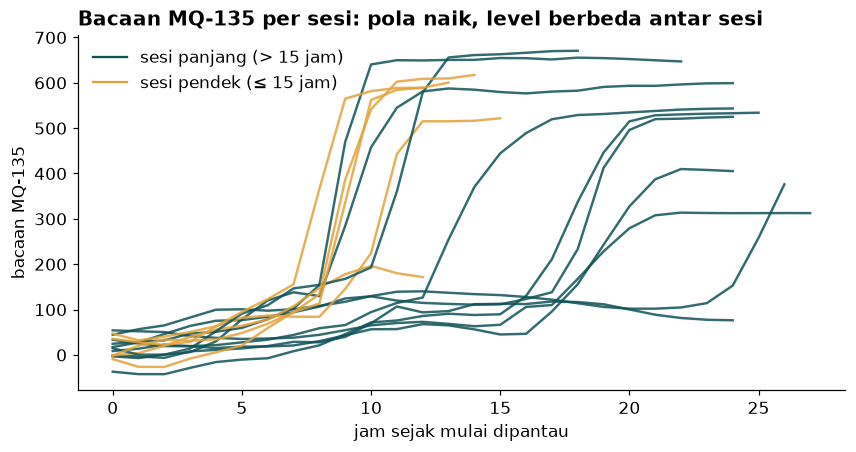

> **📌 Hasil**
>
> - 218.318 bacaan dari 15 sesi rekaman.
> - Semua sesi naik seiring waktu, tapi **puncak MQ-135 berbeda jauh**: dari 119 sampai
>   677. Model harus bisa menebak sesi yang levelnya berbeda dari yang pernah ia lihat.

In [3]:
sessions = raw.groupby("sesi").agg(bacaan=("jam", "size"), lama_jam=("jam", "max"),
                                   puncak_MQ135=("MQ-135", "max")).reset_index()
display(sessions.T)

hourly = raw.groupby(["sesi", "jam"])["MQ-135"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 4.2))
for s, d in hourly.groupby("sesi"):
    ax.plot(d.jam, d["MQ-135"], lw=1.6, color=TEAL if d.jam.max() > 15 else AMBER, alpha=0.85)
ax.plot([], [], color=TEAL, label="sesi panjang (> 15 jam)")
ax.plot([], [], color=AMBER, label="sesi pendek (≤ 15 jam)")
ax.set(xlabel="jam sejak mulai dipantau", ylabel="bacaan MQ-135",
       title="Bacaan MQ-135 per sesi: pola naik, level berbeda antar sesi")
ax.legend(loc="upper left")
save(fig, "01_mq135_per_sesi")
plt.show()

RESULTS.update(n_readings=len(raw), n_sessions=int(raw.sesi.nunique()),
               peak_min=float(sessions.puncak_MQ135.min()), peak_max=float(sessions.puncak_MQ135.max()))
result_box(f'''
- {num(len(raw))} bacaan dari {raw.sesi.nunique()} sesi rekaman.
- Semua sesi naik seiring waktu, tapi **puncak MQ-135 berbeda jauh**: dari {sessions.puncak_MQ135.min():.0f} sampai
  {sessions.puncak_MQ135.max():.0f}. Model harus bisa menebak sesi yang levelnya berbeda dari yang pernah ia lihat.
''')

---
# Bagian 4 — Membuat label Fresh / Semi-fresh / Spoiled

CSV tidak punya kolom label. Kita memakai aturan dari notebook penulis, berdasarkan **lama penyimpanan**:

| Jenis sesi | Fresh | Semi-fresh | Spoiled |
|---|---|---|---|
| Sesi panjang (> 15 jam, musim dingin) | jam ≤ 8 | 8 < jam ≤ 16 | jam > 16 |
| Sesi pendek (≤ 15 jam, setelah musim dingin) | jam ≤ 5 | 5 < jam ≤ 10 | jam > 10 |

Batasnya berbeda karena ayam lebih cepat busuk saat udara lebih hangat.

**Catatan:** label ini berasal dari waktu penyimpanan, bukan dari uji laboratorium per sampel. Jadi label
adalah *perkiraan* kondisi ayam. Karena label dibuat dari waktu, **waktu tidak boleh dipakai sebagai fitur**.
Jika waktu dipakai, model hanya mempelajari lama penyimpanan, bukan pola gas (*data leakage*).

In [4]:
long_session = raw.groupby("sesi")["jam"].transform("max") > 15
limit1 = np.where(long_session, 8, 5)
limit2 = np.where(long_session, 16, 10)
raw["label"] = np.select([raw.jam <= limit1, raw.jam <= limit2], [0, 1], 2)
counts = raw.label.value_counts().sort_index()
display(pd.DataFrame({"kelas": CLASSES, "jumlah bacaan": counts.values}))

,kelas,jumlah bacaan
0,Fresh,81012
1,Semi-fresh,75342
2,Spoiled,61964


---
# Bagian 5 — Pengolahan data (*data wrangling*)

Tiga langkah, dan masing-masing ada alasannya:

**1. Rata-rata per 5 menit.** Sensor membaca ±12 kali per menit, dan bacaan yang berdekatan hampir sama.
Setiap jam dibagi menjadi 12 segmen (*window*) berdurasi 5 menit, lalu dirata-ratakan. Data menjadi lebih rapi dan
*noise* berkurang.

**2. Dua jam pertama = masa kalibrasi (*warm-up*) sensor.** Sensor gas butuh waktu untuk stabil. Penulis aslinya juga membuang
baris awal tiap sesi. Dua jam pertama (selalu Fresh) **tidak ikut dinilai**. Bacaan jam ke-1 dipakai sebagai
**baseline** untuk sesi itu.

**3. Membuat 19 fitur yang menggambarkan gas dengan 3 cara**, ditambah kelembapan:

| Kelompok fitur | Artinya | Kenapa perlu |
|---|---|---|
| `level_` (6) | seberapa **banyak** gas (skala log) | log membuat angka besar dan kecil sebanding |
| `proporsi_` (6) | **proporsi relatif** tiap sensor terhadap total gas | polanya tetap sama walau level gas sesi berbeda |
| `naik_` (6) | **perubahan terhadap baseline** (rata-rata jam ke-1) | mirip Rs/R0 di skripsi Erlangga; menghilangkan beda alat/sampel antar sesi |
| `Kelembapan` (1) | kelembapan udara | kondisi lingkungan |

Semua fitur hanya memakai data **masa lalu** dari sesi itu sendiri, jadi bisa dihitung langsung di alat sungguhan.

**Bagaimana dengan data tidak seimbang (*imbalanced*)?** Kita cek jumlah tiap kelas. Kalau perbandingannya
tidak jauh, teknik seperti SMOTE tidak diperlukan.

218.318 bacaan → 3.828 segmen 5 menit → 3.468 segmen setelah masa kalibrasi
19 fitur per segmen


,level_MQ-135,level_MQ-2,level_MQ-3,level_MQ-6,level_MQ-7,level_MQ-9,proporsi_MQ-135,proporsi_MQ-2,proporsi_MQ-3,proporsi_MQ-6,proporsi_MQ-7,proporsi_MQ-9,naik_MQ-135,naik_MQ-2,naik_MQ-3,naik_MQ-6,naik_MQ-7,naik_MQ-9,Kelembapan
0,3.993,4.121,4.481,3.695,3.467,3.860,0.167,0.190,0.274,0.123,0.097,0.146,0.021,0.132,0.111,-0.035,0.055,-0.041,1.645
1,3.982,4.125,4.488,3.696,3.472,3.869,0.165,0.190,0.275,0.123,0.098,0.147,0.011,0.137,0.118,-0.034,0.060,-0.033,1.608
2,3.972,4.133,4.496,3.696,3.490,3.869,0.162,0.191,0.276,0.122,0.099,0.146,0.000,0.144,0.126,-0.034,0.078,-0.032,1.473
3,3.984,4.161,4.515,3.696,3.497,3.871,0.162,0.194,0.278,0.121,0.098,0.144,0.012,0.173,0.146,-0.033,0.084,-0.031,1.463
4,3.960,4.147,4.511,3.683,3.495,3.852,0.160,0.194,0.280,0.121,0.099,0.143,-0.011,0.159,0.141,-0.046,0.083,-0.049,1.510


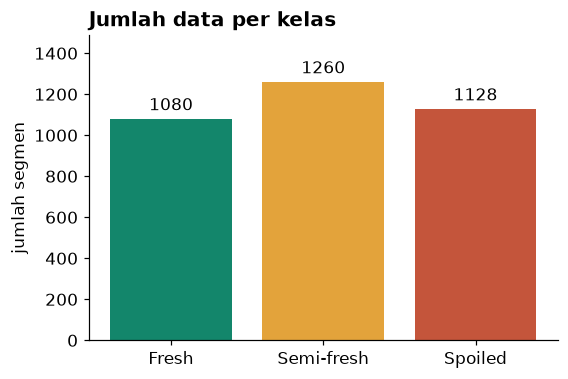

> **📌 Hasil**
>
> - 218.318 bacaan diringkas menjadi **3.468 segmen 5 menit** dengan **19 fitur**.
> - Jumlah per kelas: Fresh 1.080, Semi-fresh 1.260, Spoiled 1.128.
>   Perbandingan terbesar : terkecil = **1,17**, jadi data **cukup seimbang**. Penanganan imbalance
>   seperti SMOTE tidak diperlukan.

In [5]:
def make_windows(readings):
    # split every hour of every session into 12 five-minute windows and average them
    r = readings.copy()
    r["urutan"] = r.groupby(["sesi", "jam"]).cumcount()
    r["n"] = r.groupby(["sesi", "jam"])["jam"].transform("size")
    r["segmen"] = r.urutan * 12 // r.n
    return r.groupby(["sesi", "jam", "segmen"]).agg(**{c: (c, "mean") for c in SENSORS},
                                                    label=("label", "first")).reset_index()


def make_features(win):
    # returns (features, rows) for windows after the 2-hour calibration period
    level = np.log1p(win[MQ].clip(lower=0))
    reference = level.where(win.jam == 1).groupby(win.sesi).transform("mean")
    keep = (win.jam >= 2).to_numpy()
    rows = win[keep].reset_index(drop=True)
    level, reference = level[keep].reset_index(drop=True), reference[keep].reset_index(drop=True)
    gas = rows[MQ].clip(lower=0)
    features = pd.concat([level.add_prefix("level_"),
                          gas.div(gas.sum(axis=1) + 1, axis=0).add_prefix("proporsi_"),
                          (level - reference).add_prefix("naik_"),
                          rows[["Kelembapan"]]], axis=1)
    return features, rows


windows = make_windows(raw)
features, data = make_features(windows)
X = features.to_numpy()
y = data.label.to_numpy()
groups = data.sesi.to_numpy()
X_raw = data[SENSORS].to_numpy()                                         # for comparison: averages only
X_no_rise = features.drop(columns=[c for c in features if c.startswith("naik_")]).to_numpy()

class_counts = np.bincount(y, minlength=3)
ratio = class_counts.max() / class_counts.min()
print(f"{num(len(raw))} bacaan → {num(len(windows))} segmen 5 menit → {num(len(data))} segmen setelah masa kalibrasi")
print(f"{X.shape[1]} fitur per segmen")
display(features.head().round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(CLASSES, class_counts, color=CLASS_COLORS)
ax.bar_label(bars, padding=3)
ax.set(ylabel="jumlah segmen", title="Jumlah data per kelas", ylim=(0, class_counts.max() * 1.18))
save(fig, "02_jumlah_kelas")
plt.show()

RESULTS.update(n_windows_all=len(windows), n_windows=len(data), n_features=X.shape[1],
               class_counts=dict(zip(CLASSES, class_counts.tolist())), class_ratio=float(ratio))
result_box(f'''
- {num(len(raw))} bacaan diringkas menjadi **{num(len(data))} segmen 5 menit** dengan **{X.shape[1]} fitur**.
- Jumlah per kelas: Fresh {num(class_counts[0])}, Semi-fresh {num(class_counts[1])}, Spoiled {num(class_counts[2])}.
  Perbandingan terbesar : terkecil = **{fmt(ratio, 2)}**, jadi data **cukup seimbang**. Penanganan imbalance
  seperti SMOTE tidak diperlukan.
''')

---
# Bagian 6 — Skema validasi dan pencegahan *data leakage*

**Masalahnya:** segmen 5 menit yang berurutan dalam satu sesi isinya hampir sama. Kalau data dibagi **acak**,
menit ke-100 bisa masuk data latih dan menit ke-105 masuk data uji. Model cenderung menghafal pola sesi tersebut, sehingga
skornya terlalu tinggi (*overestimate*). Kondisi ini disebut **data leakage**.

**Solusinya: validasi Leave-One-Session-Out (LOSO).**
1. Sembunyikan **1 sesi** sebagai ujian.
2. Latih model dengan **14 sesi** lainnya.
3. Ulangi 15 kali sampai setiap sesi pernah jadi ujian.

Ini meniru kondisi nyata: alat dipakai untuk **ayam baru** yang belum pernah dilihat model.

**Ukuran skor:**
- **Akurasi:** persentase prediksi yang benar.
- **Macro-F1:** skor 0–1 yang menghitung ketiga kelas secara setara (makin tinggi makin baik). Ini ukuran utama.

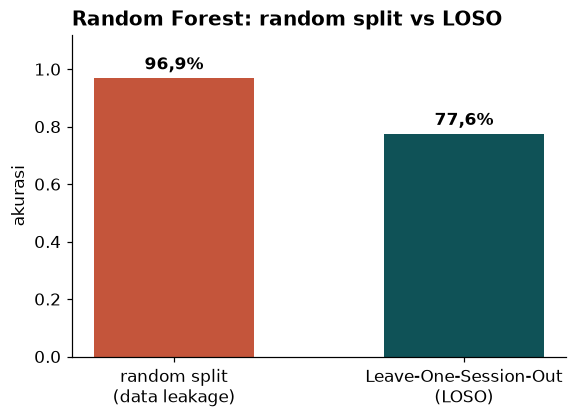

> **📌 Hasil**
>
> - Dibagi acak: akurasi **96,9%**. Diuji per sesi (LOSO): **77,6%**.
> - Paper aslinya menemukan hal yang sama: Random Forest 100% dengan data acak, tetapi 69% tanpa pembagian acak.
> - Mulai sekarang **semua hasil memakai LOSO**.

In [6]:
def loso(make_model, X_, y_=None, g_=None):
    # every window is predicted by a model that never saw its session
    y_ = y if y_ is None else y_
    g_ = groups if g_ is None else g_
    pred = np.empty_like(y_)
    proba = np.zeros((len(y_), 3))
    for train, test in LeaveOneGroupOut().split(X_, y_, g_):
        model = make_model()
        model.fit(X_[train], y_[train])
        pred[test] = model.predict(X_[test])
        proba[test] = model.predict_proba(X_[test])
    return pred, proba


def scores(pred, y_=None, g_=None):
    y_ = y if y_ is None else y_
    g_ = groups if g_ is None else g_
    per_session = [accuracy_score(y_[g_ == s], pred[g_ == s]) for s in np.unique(g_)]
    return {"akurasi": accuracy_score(y_, pred), "macro_f1": f1_score(y_, pred, average="macro"),
            "akurasi_sesi_terburuk": min(per_session)}


make_rf = lambda: RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEED, n_jobs=-1)

pred_random = np.empty_like(y)
for train, test in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
    pred_random[test] = make_rf().fit(X[train], y[train]).predict(X[test])
pred_loso, _ = loso(make_rf, X)
leak = {"acak": scores(pred_random), "loso": scores(pred_loso)}

fig, ax = plt.subplots(figsize=(5.8, 3.8))
vals = [leak["acak"]["akurasi"], leak["loso"]["akurasi"]]
bars = ax.bar(["random split\n(data leakage)", "Leave-One-Session-Out\n(LOSO)"], vals, color=[RED, TEAL], width=0.55)
ax.bar_label(bars, labels=[pct(v) for v in vals], padding=3, fontweight="bold")
ax.set(ylim=(0, 1.12), ylabel="akurasi", title="Random Forest: random split vs LOSO")
save(fig, "03_kebocoran")
plt.show()

RESULTS["leakage"] = leak
result_box(f'''
- Dibagi acak: akurasi **{pct(leak["acak"]["akurasi"])}**. Diuji per sesi (LOSO): **{pct(leak["loso"]["akurasi"])}**.
- Paper aslinya menemukan hal yang sama: Random Forest 100% dengan data acak, tetapi 69% tanpa pembagian acak.
- Mulai sekarang **semua hasil memakai LOSO**.
''')

---
# Bagian 7 — Ensemble learning

**Idenya:** satu model bisa salah. Kalau banyak model digabung, kesalahan satu model bisa ditutup model lain.
Mirip minta pendapat banyak orang sebelum mengambil keputusan.

| Jenis | Model | Cara kerja sederhana |
|---|---|---|
| tunggal | Logistic Regression | menarik garis pemisah antar kelas |
| tunggal | KNN | melihat 15 data terdekat, ikut suara terbanyak |
| tunggal | Decision Tree | satu pohon keputusan "jika… maka…" (kedalaman 6) |
| **ensemble – bagging** | **Random Forest** | 300 pohon (kedalaman 6, sama dengan Decision Tree), masing-masing dilatih dengan sampel data berbeda, lalu voting |
| **ensemble – boosting** | **XGBoost** | 200 pohon kecil dibuat berurutan, tiap pohon memperbaiki kesalahan pohon sebelumnya |
| **ensemble – voting** | **Voting** | gabungan Logistic Regression + Random Forest + XGBoost, peluang ketiganya dirata-rata |

Pengaturan setiap model **ditetapkan dari awal**. *Hyperparameter* tidak di-*tuning* menggunakan data uji,
karena hal itu juga menimbulkan *data leakage*.

**Catatan:** angka XGBoost dan Voting bisa berbeda sekitar ±0,02 kalau dijalankan di jenis komputer lain
(misalnya laptop Mac vs Google Colab), karena XGBoost menghitung secara paralel dan pembulatan angkanya sedikit
berbeda antar prosesor. Angka di slide berasal dari run yang tersimpan di notebook ini. Model lain dan
kesimpulannya tidak berubah: semua ensemble tetap di atas semua model tunggal.

,model,jenis,akurasi,macro_f1,akurasi_sesi_terburuk,f1_weighted,recall_spoiled
0,Logistic Regression,tunggal,"72,2%",0.729,"45,8%",0.724,"72,7%"
1,KNN,tunggal,"72,7%",0.736,"50,8%",0.731,"74,3%"
2,Decision Tree,tunggal,"70,4%",0.713,"53,2%",0.710,"67,3%"
3,Random Forest,ensemble,"77,6%",0.782,"55,3%",0.778,"77,5%"
4,XGBoost,ensemble,"76,0%",0.765,"54,5%",0.761,"84,2%"
5,Voting,ensemble,"75,0%",0.756,"52,3%",0.752,"77,8%"


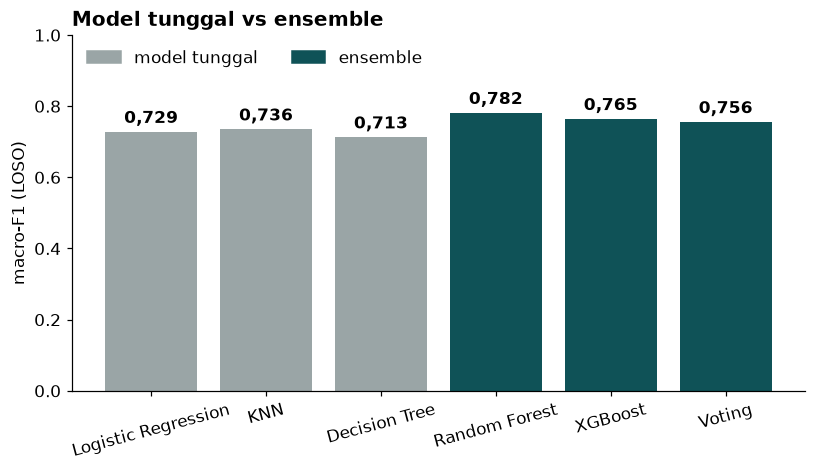

In [7]:
def make_xgb():
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, n_jobs=4)


MODELS = {
    "Logistic Regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "KNN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Decision Tree": lambda: DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "Random Forest": make_rf,
    "XGBoost": make_xgb,
    "Voting": lambda: VotingClassifier([
        ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
        ("rf", make_rf()), ("xgb", make_xgb())], voting="soft"),
}
KIND = {"Logistic Regression": "tunggal", "KNN": "tunggal", "Decision Tree": "tunggal",
        "Random Forest": "ensemble", "XGBoost": "ensemble", "Voting": "ensemble"}

model_rows, predictions, probabilities = [], {}, {}
for name, make_model in MODELS.items():
    predictions[name], probabilities[name] = loso(make_model, X)
    model_rows.append({"model": name, "jenis": KIND[name], **scores(predictions[name]),
                       "f1_weighted": f1_score(y, predictions[name], average="weighted"),
                       "recall_spoiled": recall_score(y, predictions[name], labels=[2], average="macro")})
model_table = pd.DataFrame(model_rows)
display(model_table.assign(akurasi=model_table.akurasi.map(pct),
                           macro_f1=model_table.macro_f1.round(3),
                           f1_weighted=model_table.f1_weighted.round(3),
                           recall_spoiled=model_table.recall_spoiled.map(pct),
                           akurasi_sesi_terburuk=model_table.akurasi_sesi_terburuk.map(pct)))

fig, ax = plt.subplots(figsize=(8.6, 4.2))
bars = ax.bar(model_table.model, model_table.macro_f1,
              color=[GREY if k == "tunggal" else TEAL for k in model_table.jenis])
ax.bar_label(bars, labels=[fmt(v) for v in model_table.macro_f1], padding=3, fontweight="bold")
ax.set(ylim=(0, 1), ylabel="macro-F1 (LOSO)", title="Model tunggal vs ensemble")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GREY), plt.Rectangle((0, 0), 1, 1, color=TEAL)],
          labels=["model tunggal", "ensemble"], loc="upper left", ncol=2)
plt.xticks(rotation=15)
save(fig, "04_ensemble")
plt.show()

### Seberapa besar pengaruh pengolahan data?
Random Forest yang sama dilatih dengan 3 versi fitur: rata-rata mentah saja, ditambah log-level dan proporsi relatif, lalu
ditambah perubahan terhadap baseline.

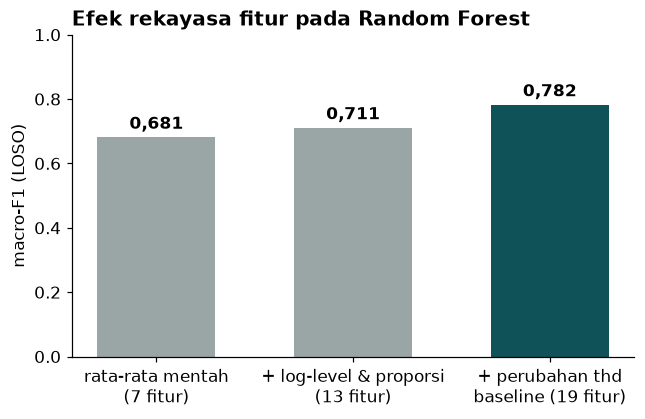

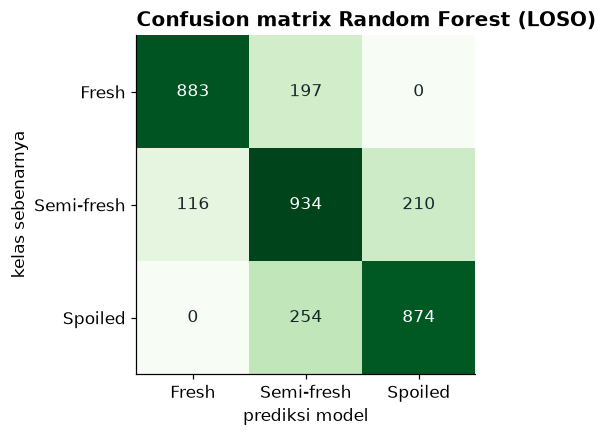

,sesi,akurasi,puncak_MQ135
0,9,"55,3%",206.0
1,1,"59,8%",119.0
2,2,"60,0%",419.0


> **📌 Hasil**
>
> - Ensemble terbaik: **Random Forest macro-F1 0,782** (akurasi 77,6%).
>   Model tunggal terbaik: KNN 0,736.
> - Rata-rata ensemble 0,768 vs rata-rata model tunggal 0,726.
> - Random Forest (banyak pohon) vs Decision Tree (satu pohon, kedalaman sama):
>   0,782 vs
>   0,713.
> - Pengolahan data menaikkan Random Forest dari 0,681 ke 0,782.
> - Kelas yang paling sulit: **Semi-fresh** (recall 74%), karena letaknya di tengah, di antara segar dan busuk.
> - Sesi tersulit: sesi 9 (55,3%, puncak MQ-135 206), sesi 1 (59,8%, puncak MQ-135 119), sesi 2 (60,0%, puncak MQ-135 419).
>   Median puncak MQ-135 semua sesi: 535.

In [8]:
wrangling = {
    "rata-rata mentah\n(7 fitur)": scores(loso(make_rf, X_raw)[0])["macro_f1"],
    "+ log-level & proporsi\n(13 fitur)": scores(loso(make_rf, X_no_rise)[0])["macro_f1"],
    "+ perubahan thd\nbaseline (19 fitur)": scores(predictions["Random Forest"])["macro_f1"],
}
fig, ax = plt.subplots(figsize=(6.6, 3.8))
bars = ax.bar(list(wrangling), list(wrangling.values()), color=[GREY, GREY, TEAL], width=0.6)
ax.bar_label(bars, labels=[fmt(v) for v in wrangling.values()], padding=3, fontweight="bold")
ax.set(ylim=(0, 1), ylabel="macro-F1 (LOSO)", title="Efek rekayasa fitur pada Random Forest")
save(fig, "05_efek_wrangling")
plt.show()

best_rf = predictions["Random Forest"]
cm = confusion_matrix(y, best_rf)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Greens")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else INK)
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES, xlabel="prediksi model",
       ylabel="kelas sebenarnya", title="Confusion matrix Random Forest (LOSO)")
save(fig, "06_confusion_rf")
plt.show()

single = model_table[model_table.jenis == "tunggal"]
ensemble = model_table[model_table.jenis == "ensemble"]
best_single = single.loc[single.macro_f1.idxmax()]
best_ens = ensemble.loc[ensemble.macro_f1.idxmax()]
recall = cm.diagonal() / cm.sum(axis=1)
per_session = pd.Series({int(s): accuracy_score(y[groups == s], best_rf[groups == s]) for s in np.unique(groups)})
peaks = sessions.set_index("sesi").puncak_MQ135
hardest = [{"sesi": s, "akurasi": float(a), "puncak_MQ135": float(peaks[s])} for s, a in per_session.nsmallest(3).items()]
display(pd.DataFrame(hardest).assign(akurasi=lambda d: d.akurasi.map(pct)))
RESULTS.update(per_session_accuracy=per_session.round(4).to_dict(), hardest_sessions=hardest)
RESULTS.update(models=model_rows, wrangling={k.replace("\n", " "): v for k, v in wrangling.items()},
               confusion_rf=cm.tolist(), recall_rf=dict(zip(CLASSES, recall.round(3).tolist())))
result_box(f'''
- Ensemble terbaik: **{best_ens.model} macro-F1 {fmt(best_ens.macro_f1)}** (akurasi {pct(best_ens.akurasi)}).
  Model tunggal terbaik: {best_single.model} {fmt(best_single.macro_f1)}.
- Rata-rata ensemble {fmt(ensemble.macro_f1.mean())} vs rata-rata model tunggal {fmt(single.macro_f1.mean())}.
- Random Forest (banyak pohon) vs Decision Tree (satu pohon, kedalaman sama):
  {fmt(model_table.set_index("model").macro_f1["Random Forest"])} vs
  {fmt(model_table.set_index("model").macro_f1["Decision Tree"])}.
- Pengolahan data menaikkan Random Forest dari {fmt(list(wrangling.values())[0])} ke {fmt(list(wrangling.values())[-1])}.
- Kelas yang paling sulit: **Semi-fresh** (recall {recall[1]:.0%}), karena letaknya di tengah, di antara segar dan busuk.
- Sesi tersulit: {", ".join(f"sesi {h['sesi']} ({pct(h['akurasi'])}, puncak MQ-135 {h['puncak_MQ135']:.0f})" for h in hardest)}.
  Median puncak MQ-135 semua sesi: {peaks.median():.0f}.
''')

---
# Bagian 8 — Augmentasi data

**Kenapa perlu:** kita hanya punya **15 sesi**. Alat sungguhan nanti bisa punya sensor yang sedikit lebih atau
kurang peka, dan bacaannya bisa lebih berisik. Augmentasi membuat **data latih tambahan buatan** untuk
meniru variasi itu.

**Bagaimana caranya** (2 salinan buatan per sesi latih):
- **Jitter:** menambahkan derau acak kecil (5% dari variasi sensor), seperti sensor yang bergetar.
- **Variasi sensitivitas sensor:** mengalikan bacaan tiap sensor dengan faktor acak (sekitar ±30%) per sesi, seolah-olah
  kita punya alat e-nose lain.

**Aturan penting:** augmentasi **hanya untuk data latih**. Data uji selalu data asli.

model,Decision Tree,Random Forest
augmentasi,,
tanpa,0.713,0.782
jitter,0.698,0.773
sensitivitas,0.724,0.767


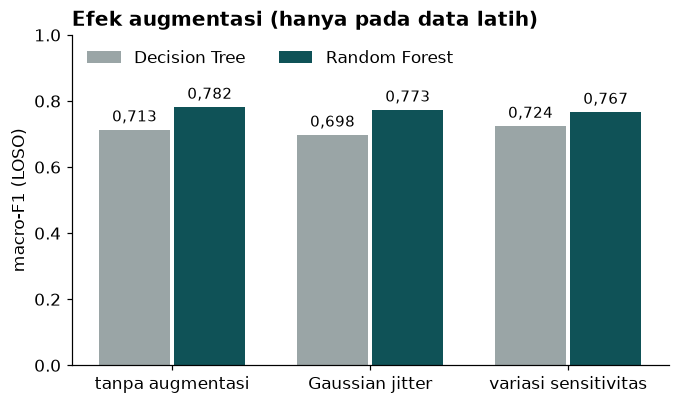

> **📌 Hasil**
>
> - Decision Tree: jitter -0,016, variasi sensitivitas +0,011.
> - Random Forest: jitter -0,009, variasi sensitivitas -0,015.
> - Artinya: data buatan **tidak otomatis menaikkan skor**. Variasi buatan tidak sama dengan perbedaan nyata antar
>   sesi ayam. Bagian 9 menunjukkan bahwa **sesi asli tambahan** jauh lebih berguna.

In [9]:
def augment(train_windows, rng, method, copies=2):
    out = []
    for k in range(copies):
        a = train_windows.copy()
        if method == "jitter":
            a[MQ] = a[MQ] + rng.normal(0, 0.05, (len(a), len(MQ))) * train_windows[MQ].std().to_numpy()
        if method == "sensitivitas":
            for s in a.sesi.unique():
                rows = a.sesi == s
                a.loc[rows, MQ] = a.loc[rows, MQ] * np.exp(rng.normal(0, 0.3, len(MQ)))
        a["sesi"] = a["sesi"] + 100 * (k + 1)  # a synthetic copy behaves like a new session
        out.append(a)
    return pd.concat(out, ignore_index=True)


AUG_MODELS = {"Decision Tree": MODELS["Decision Tree"], "Random Forest": make_rf}
aug_rows = []
for method in ["tanpa", "jitter", "sensitivitas"]:
    for name, make_model in AUG_MODELS.items():
        rng = np.random.default_rng(SEED)
        pred = np.empty_like(y)
        for test_session in np.unique(groups):
            train = groups != test_session
            X_train, y_train = X[train], y[train]
            if method != "tanpa":
                synthetic = augment(windows[windows.sesi != test_session], rng, method)
                f_aug, d_aug = make_features(synthetic)
                X_train = np.vstack([X_train, f_aug.to_numpy()])
                y_train = np.concatenate([y_train, d_aug.label.to_numpy()])
            pred[~train] = make_model().fit(X_train, y_train).predict(X[~train])
        aug_rows.append({"augmentasi": method, "model": name, **scores(pred)})
aug_table = pd.DataFrame(aug_rows)
display(aug_table.pivot(index="augmentasi", columns="model", values="macro_f1").loc[["tanpa", "jitter", "sensitivitas"]].round(3))

fig, ax = plt.subplots(figsize=(7, 3.9))
pos = np.arange(3)
for i, (name, color) in enumerate([("Decision Tree", GREY), ("Random Forest", TEAL)]):
    v = aug_table[aug_table.model == name].set_index("augmentasi").loc[["tanpa", "jitter", "sensitivitas"], "macro_f1"]
    bars = ax.bar(pos + (i - 0.5) * 0.38, v, 0.36, color=color, label=name)
    ax.bar_label(bars, labels=[fmt(x) for x in v], padding=3, fontsize=10)
ax.set(xticks=pos, xticklabels=["tanpa augmentasi", "Gaussian jitter", "variasi sensitivitas"], ylim=(0, 1),
       ylabel="macro-F1 (LOSO)", title="Efek augmentasi (hanya pada data latih)")
ax.legend(loc="upper left", ncol=2)
save(fig, "07_augmentasi")
plt.show()

aug_pivot = aug_table.pivot(index="augmentasi", columns="model", values="macro_f1")
RESULTS["augmentation"] = aug_rows
delta = {m: {k: float(aug_pivot.loc[k, m] - aug_pivot.loc["tanpa", m]) for k in ["jitter", "sensitivitas"]}
         for m in AUG_MODELS}
result_box(f'''
- Decision Tree: jitter {signed(delta["Decision Tree"]["jitter"])}, variasi sensitivitas {signed(delta["Decision Tree"]["sensitivitas"])}.
- Random Forest: jitter {signed(delta["Random Forest"]["jitter"])}, variasi sensitivitas {signed(delta["Random Forest"]["sensitivitas"])}.
- Artinya: data buatan **tidak otomatis menaikkan skor**. Variasi buatan tidak sama dengan perbedaan nyata antar
  sesi ayam. Bagian 9 menunjukkan bahwa **sesi asli tambahan** jauh lebih berguna.
''')

---
# Bagian 9 — Reinforcement learning: agen yang belajar mengambil keputusan

Rubrik dosen: *bagaimana tambahan **iterasi** dan **data** dapat meningkatkan performa sistem sesuai tujuan.*

**Tujuan sistem:** tidak hanya memprediksi kelas, tetapi juga **mengambil keputusan** yang aman dan tidak boros:
- **Jual:** ayam dianggap masih layak.
- **Cek manual:** minta orang atau lab mengecek dulu. Ada biaya, tapi keputusannya pasti benar.
- **Buang:** ayam dianggap busuk.

**Agen reinforcement learning** belajar sendiri lewat *trial and error*:

| Unsur RL | Di proyek ini |
|---|---|
| **State** (yang dilihat agen) | prediksi Random Forest (Fresh/Semi-fresh/Spoiled) × model **yakin** atau **ragu** (peluang ≥ 0,7 atau < 0,7) → 6 state |
| **Aksi** | Jual, Cek manual, Buang |
| **Reward** (asumsi kami) | lihat tabel di bawah |
| **Cara belajar** | **ε-greedy**: 90% pilih aksi terbaik sejauh ini, 10% coba acak. Nilai tiap aksi diperbarui dengan rata-rata reward yang didapat (seperti materi *multi-armed bandit*). |

**Tabel reward.** "Layak" = Fresh atau Semi-fresh, "busuk" = Spoiled. Angkanya **asumsi kami**: menjual ayam
busuk dianggap paling berbahaya.

| Aksi | Ayam layak | Ayam busuk |
|---|---|---|
| Jual | +1 | **−5** (konsumen dirugikan) |
| Cek manual | +0,5 | +0,5 (aman, tapi ada biaya cek) |
| Buang | −1 (mubazir) | +1 |

**Validasi:** agen belajar dari 12 sesi dan **dinilai pada 3 sesi lain** (5 putaran, setiap sesi pernah jadi
ujian). Pembagian sesinya ditulis tetap supaya hasilnya sama di komputer mana pun. Prediksi Random Forest yang dipakai berasal dari model yang tidak pernah melihat sesi tersebut.

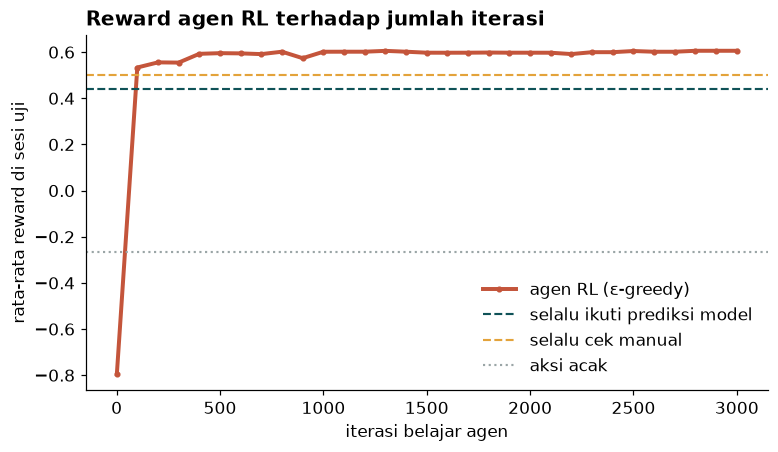

,state,jumlah data,aksi yang dipelajari
0,Fresh (yakin),811,Jual
1,Fresh (ragu),188,Jual
2,Semi-fresh (yakin),655,Cek manual
3,Semi-fresh (ragu),730,Cek manual
4,Spoiled (yakin),833,Buang
5,Spoiled (ragu),251,Cek manual


,proporsi Spoiled,Jual,Cek manual,Buang
Fresh (yakin),0.00,1.00,0.5,-1.00
Fresh (ragu),0.00,1.00,0.5,-1.00
Semi-fresh (yakin),0.11,0.35,0.5,-0.78
Semi-fresh (ragu),0.25,-0.50,0.5,-0.50
Spoiled (yakin),0.88,-4.25,0.5,0.75
Spoiled (ragu),0.58,-2.47,0.5,0.16


,,agen RL,selalu ikuti prediksi model
0,ayam busuk yang terjual,0,254
1,ayam layak yang terbuang,104,210
2,kasus yang dicek manual,"47,2%",0%


In [10]:
proba_rf = probabilities["Random Forest"]
predicted = proba_rf.argmax(axis=1)
unsure = proba_rf.max(axis=1) < 0.7
state = predicted * 2 + unsure
STATE_NAMES = [f"{c} ({'ragu' if u else 'yakin'})" for c in CLASSES for u in (False, True)]
ACTIONS = ["Jual", "Cek manual", "Buang"]
fit_to_sell = y <= 1
REWARD = np.column_stack([np.where(fit_to_sell, 1.0, -5.0), np.full(len(y), 0.5),
                          np.where(fit_to_sell, -1.0, 1.0)])


def train_agent(train_idx, test_idx, seed, steps=3000, eps=0.1, every=100):
    rng = np.random.default_rng(seed)
    Q, N = np.zeros((6, 3)), np.zeros((6, 3))
    curve = []
    for t in range(1, steps + 1):
        i = rng.choice(train_idx)                       # the agent meets one chicken sample
        s = state[i]
        a = rng.integers(3) if rng.random() < eps else int(np.argmax(Q[s]))
        N[s, a] += 1
        Q[s, a] += (REWARD[i, a] - Q[s, a]) / N[s, a]    # running average of the reward
        if t == 1 or t % every == 0:
            policy = Q.argmax(axis=1)
            curve.append(REWARD[test_idx, policy[state[test_idx]]].mean())
    return Q, np.array(curve)


# fixed session split: GroupKFold orders equal-sized sessions differently on different machines
RL_TEST_SESSIONS = [[0, 10, 11], [2, 8, 13], [1, 6, 9], [4, 7, 14], [3, 5, 12]]
folds = [(np.flatnonzero(~np.isin(groups, test)), np.flatnonzero(np.isin(groups, test))) for test in RL_TEST_SESSIONS]
curves, policies, trust_model, always_check, random_act = [], [], [], [], []
for train_idx, test_idx in folds:
    for seed in range(5):
        Q, c = train_agent(train_idx, test_idx, seed)
        curves.append(c)
        policies.append(Q.argmax(axis=1))
    trust_model.append(np.where(predicted[test_idx] <= 1, REWARD[test_idx, 0], REWARD[test_idx, 2]).mean())
    always_check.append(0.5)
    random_act.append(REWARD[test_idx].mean())
curves = np.array(curves)
steps_axis = np.r_[1, np.arange(100, 3001, 100)]
agent_final = curves[:, -1].mean()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(steps_axis, curves.mean(axis=0), color=RED, lw=2.6, marker="o", ms=3, label="agen RL (ε-greedy)")
ax.axhline(np.mean(trust_model), color=TEAL, ls="--", lw=1.4, label="selalu ikuti prediksi model")
ax.axhline(0.5, color=AMBER, ls="--", lw=1.4, label="selalu cek manual")
ax.axhline(np.mean(random_act), color=GREY, ls=":", lw=1.4, label="aksi acak")
ax.set(xlabel="iterasi belajar agen", ylabel="rata-rata reward di sesi uji",
       title="Reward agen RL terhadap jumlah iterasi")
ax.legend(loc="lower right")
save(fig, "08_rl_kurva")
plt.show()

policy_mode = [int(np.bincount([p[s] for p in policies], minlength=3).argmax()) for s in range(6)]
policy_table = pd.DataFrame({"state": STATE_NAMES, "jumlah data": np.bincount(state, minlength=6),
                             "aksi yang dipelajari": [ACTIONS[a] for a in policy_mode]})
display(policy_table)

# true average reward of each action per state: the values the agent estimates by trial and error
state_reward = pd.DataFrame([[REWARD[state == s, a].mean() for a in range(3)] for s in range(6)],
                            index=STATE_NAMES, columns=ACTIONS)
state_reward.insert(0, "proporsi Spoiled", [float((~fit_to_sell[state == s]).mean()) for s in range(6)])
display(state_reward.round(2))

# what the learned rules do when applied to every window
action = np.array(policy_mode)[state]
impact = {"porsi_jual": float((action == 0).mean()), "porsi_cek": float((action == 1).mean()),
          "porsi_buang": float((action == 2).mean()),
          "busuk_terjual_agen": int(((action == 0) & ~fit_to_sell).sum()),
          "busuk_terjual_ikut_model": int(((predicted <= 1) & ~fit_to_sell).sum()),
          "layak_terbuang_agen": int(((action == 2) & fit_to_sell).sum()),
          "layak_terbuang_ikut_model": int(((predicted == 2) & fit_to_sell).sum()),
          "n_busuk": int((~fit_to_sell).sum()), "n_layak": int(fit_to_sell.sum())}
display(pd.DataFrame({"": ["ayam busuk yang terjual", "ayam layak yang terbuang", "kasus yang dicek manual"],
                      "agen RL": [impact["busuk_terjual_agen"], impact["layak_terbuang_agen"], pct(impact["porsi_cek"])],
                      "selalu ikuti prediksi model": [impact["busuk_terjual_ikut_model"],
                                                    impact["layak_terbuang_ikut_model"], "0%"]}))
RESULTS["rl"] = {"reward_start": float(curves[:, 0].mean()), "reward_after_100": float(curves[:, 1].mean()),
                 "reward_final": float(agent_final), "trust_model": float(np.mean(trust_model)),
                 "always_check": 0.5, "random_action": float(np.mean(random_act)),
                 "policy": dict(zip(STATE_NAMES, [ACTIONS[a] for a in policy_mode])),
                 "curve": curves.mean(axis=0).round(4).tolist(), "steps": steps_axis.tolist(), "impact": impact,
                 "state_counts": dict(zip(STATE_NAMES, np.bincount(state, minlength=6).tolist())),
                 "state_reward": state_reward.round(4).to_dict("index")}

### Efek tambah data: tambah sesi ayam asli
Pertanyaan kedua di rubrik: apakah **tambahan data** meningkatkan performa? Untuk setiap sesi uji, Random Forest
dilatih dengan 1, 2, 4, … sampai 14 sesi lain yang dipilih acak.

,sesi_latih,mean,std
0,1,0.579,0.241
1,2,0.603,0.210
2,4,0.668,0.216
3,6,0.704,0.167
4,8,0.742,0.143
5,10,0.719,0.186
6,12,0.729,0.158
7,14,0.752,0.162


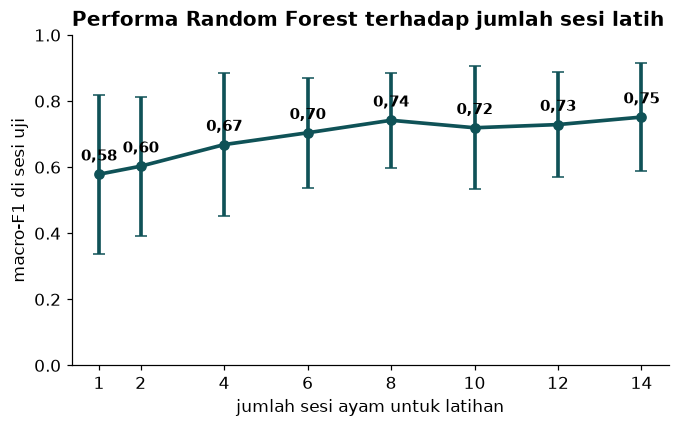

> **📌 Hasil**
>
> - **Tambahan iterasi:** reward agen naik dari -0,80 (iterasi pertama) ke
>   0,53 setelah 100 iterasi, lalu stabil di **0,61**.
> - Agen mengalahkan "selalu ikuti prediksi model" (0,44) dan "selalu cek manual" (0,50).
> - Agen belajar: prediksi Fresh → **Jual**; Semi-fresh → **Cek manual**; Spoiled yang yakin → **Buang**.
>   Cek manual dipakai hanya saat risikonya tinggi.
> - Kalau aturan agen diterapkan ke semua data: ayam busuk yang terjual **0** dari
>   1.128 (kalau sekadar mengikuti prediksi model: 254).
>   Harganya: 47,2% kasus perlu cek manual.
> - **Tambahan data:** macro-F1 naik dari 0,58 (1 sesi) ke
>   **0,75** (14 sesi). Kurvanya sedikit naik-turun karena sesi latih dipilih
>   acak, tapi arahnya jelas naik.

In [11]:
rng = np.random.default_rng(SEED)
curve_rows = []
for k in [1, 2, 4, 6, 8, 10, 12, 14]:
    for test_session in np.unique(groups):
        others = np.setdiff1d(np.unique(groups), [test_session])
        for repeat in range(2):
            chosen = rng.choice(others, k, replace=False)
            train, test = np.isin(groups, chosen), groups == test_session
            if len(np.unique(y[train])) < 3:
                continue
            model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED, n_jobs=-1)
            pred = model.fit(X[train], y[train]).predict(X[test])
            curve_rows.append({"sesi_latih": k, "macro_f1": f1_score(y[test], pred, average="macro")})
session_curve = pd.DataFrame(curve_rows).groupby("sesi_latih").macro_f1.agg(["mean", "std"]).reset_index()
display(session_curve.round(3))

fig, ax = plt.subplots(figsize=(7, 3.9))
ax.errorbar(session_curve.sesi_latih, session_curve["mean"], yerr=session_curve["std"], color=TEAL, lw=2.4,
            marker="o", capsize=4)
for _, r in session_curve.iterrows():
    ax.annotate(fmt(r["mean"], 2), (r.sesi_latih, r["mean"]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=10, fontweight="bold")
ax.set(xlabel="jumlah sesi ayam untuk latihan", ylabel="macro-F1 di sesi uji", ylim=(0, 1),
       xticks=session_curve.sesi_latih, title="Performa Random Forest terhadap jumlah sesi latih")
save(fig, "09_tambah_sesi")
plt.show()

RESULTS["session_curve"] = session_curve.round(4).to_dict("records")
rl = RESULTS["rl"]
result_box(f'''
- **Tambahan iterasi:** reward agen naik dari {fmt(rl["reward_start"], 2)} (iterasi pertama) ke
  {fmt(rl["reward_after_100"], 2)} setelah 100 iterasi, lalu stabil di **{fmt(rl["reward_final"], 2)}**.
- Agen mengalahkan "selalu ikuti prediksi model" ({fmt(rl["trust_model"], 2)}) dan "selalu cek manual" (0,50).
- Agen belajar: prediksi Fresh → **Jual**; Semi-fresh → **Cek manual**; Spoiled yang yakin → **Buang**.
  Cek manual dipakai hanya saat risikonya tinggi.
- Kalau aturan agen diterapkan ke semua data: ayam busuk yang terjual **{rl["impact"]["busuk_terjual_agen"]}** dari
  {num(rl["impact"]["n_busuk"])} (kalau sekadar mengikuti prediksi model: {rl["impact"]["busuk_terjual_ikut_model"]}).
  Harganya: {pct(rl["impact"]["porsi_cek"])} kasus perlu cek manual.
- **Tambahan data:** macro-F1 naik dari {fmt(session_curve["mean"].iloc[0], 2)} (1 sesi) ke
  **{fmt(session_curve["mean"].iloc[-1], 2)}** (14 sesi). Kurvanya sedikit naik-turun karena sesi latih dipilih
  acak, tapi arahnya jelas naik.
''')

---
# Bagian 10 — Sensor mana yang paling penting?

Random Forest mencatat seberapa sering dan seberapa berguna tiap fitur dipakai untuk memisahkan kelas
(*feature importance*). Kita jumlahkan 3 fitur dari sensor yang sama (level + proporsi + naik).

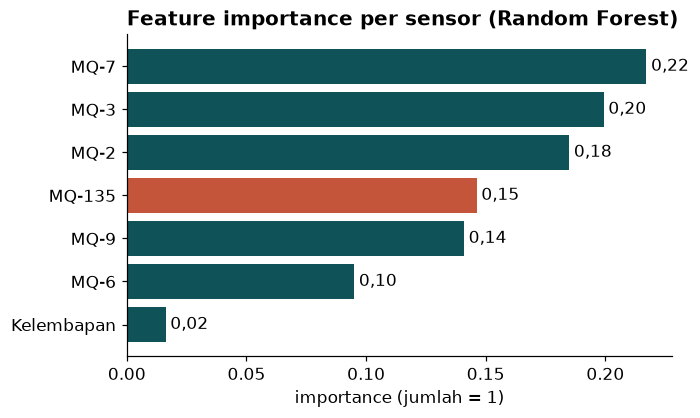

> **📌 Hasil**
>
> - Sensor paling berpengaruh: **MQ-7** (0,22), lalu MQ-3 (0,20).
> - MQ-135, sensor yang dipakai skripsi Erlangga, ada di urutan ke-4 dari 7
>   (0,15).
> - Importance hanya menunjukkan apa yang dipakai model, **bukan** sebab-akibat kimia.

In [12]:
final_rf = make_rf().fit(X, y)
importance = pd.Series(final_rf.feature_importances_, index=features.columns)
per_sensor = pd.Series({s: importance[[c for c in importance.index if c.endswith(s)]].sum() for s in SENSORS})
per_sensor = per_sensor.sort_values()

fig, ax = plt.subplots(figsize=(6.4, 3.8))
bars = ax.barh(per_sensor.index, per_sensor.values,
               color=[RED if s == "MQ-135" else TEAL for s in per_sensor.index])
ax.bar_label(bars, labels=[fmt(v, 2) for v in per_sensor.values], padding=3)
ax.set(xlabel="importance (jumlah = 1)", title="Feature importance per sensor (Random Forest)")
save(fig, "10_sensor_penting")
plt.show()

rank = per_sensor.sort_values(ascending=False)
RESULTS["sensor_importance"] = rank.round(4).to_dict()
result_box(f'''
- Sensor paling berpengaruh: **{rank.index[0]}** ({fmt(rank.iloc[0], 2)}), lalu {rank.index[1]} ({fmt(rank.iloc[1], 2)}).
- MQ-135, sensor yang dipakai skripsi Erlangga, ada di urutan ke-{list(rank.index).index("MQ-135") + 1} dari 7
  ({fmt(rank["MQ-135"], 2)}).
- Importance hanya menunjukkan apa yang dipakai model, **bukan** sebab-akibat kimia.
''')

---
# Bagian 11 — Ringkasan semua angka dan kesimpulan

In [13]:
RESULTS["source"] = {"paper": "Anwar & Anwar (2025), Sensing and Bio-Sensing Research 47, 100739",
                     "csv_sha256": SHA256}
(OUT / "ringkasan.json").write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))

m = model_table.set_index("model")
display(Markdown(f'''
| Pertanyaan | Jawaban |
|---|---|
| Berapa skor dengan *random split* (*data leakage*)? | akurasi {pct(leak["acak"]["akurasi"])} |
| Berapa skor dengan validasi LOSO? | Random Forest akurasi {pct(leak["loso"]["akurasi"])}, macro-F1 {fmt(m.macro_f1["Random Forest"])} |
| Apakah ensemble lebih baik? | ensemble terbaik {best_ens.model} {fmt(best_ens.macro_f1)} vs tunggal terbaik {best_single.model} {fmt(best_single.macro_f1)} |
| Seberapa penting pengolahan data? | Random Forest {fmt(list(wrangling.values())[0])} → {fmt(list(wrangling.values())[-1])} |
| Apakah augmentasi membantu? | Random Forest: jitter {signed(delta["Random Forest"]["jitter"])}, sensitivitas {signed(delta["Random Forest"]["sensitivitas"])} |
| Apakah tambahan iterasi membantu (RL)? | reward {fmt(rl["reward_start"], 2)} → {fmt(rl["reward_final"], 2)}; ikut model saja {fmt(rl["trust_model"], 2)} |
| Apakah tambahan data membantu? | 1 sesi {fmt(session_curve["mean"].iloc[0], 2)} → 14 sesi {fmt(session_curve["mean"].iloc[-1], 2)} |
| Sensor paling berpengaruh? | {rank.index[0]} |
'''))
print("Semua angka tersimpan di hasil/ringkasan.json; grafik di folder hasil/.")


| Pertanyaan | Jawaban |
|---|---|
| Berapa skor dengan *random split* (*data leakage*)? | akurasi 96,9% |
| Berapa skor dengan validasi LOSO? | Random Forest akurasi 77,6%, macro-F1 0,782 |
| Apakah ensemble lebih baik? | ensemble terbaik Random Forest 0,782 vs tunggal terbaik KNN 0,736 |
| Seberapa penting pengolahan data? | Random Forest 0,681 → 0,782 |
| Apakah augmentasi membantu? | Random Forest: jitter -0,009, sensitivitas -0,015 |
| Apakah tambahan iterasi membantu (RL)? | reward -0,80 → 0,61; ikut model saja 0,44 |
| Apakah tambahan data membantu? | 1 sesi 0,58 → 14 sesi 0,75 |
| Sensor paling berpengaruh? | MQ-7 |


Semua angka tersimpan di hasil/ringkasan.json; grafik di folder hasil/.


## Kesimpulan
1. **Skema validasi sangat menentukan.** *Random split* memberi skor hampir sempurna karena *data leakage*.
   Validasi LOSO memberi estimasi performa yang realistis.
2. **Pengolahan data adalah langkah terpenting.** Kalibrasi per sesi (perubahan terhadap baseline jam pertama) membuat model
   bisa menilai ayam dari sesi yang levelnya berbeda.
3. **Ensemble lebih baik dari model tunggal**, terutama banyak pohon (Random Forest) dibanding satu pohon.
4. **Augmentasi buatan tidak menggantikan data asli.** Yang menaikkan skor adalah **sesi ayam asli tambahan**.
5. **Agen reinforcement learning** belajar kapan cukup percaya model dan kapan perlu cek manual, sehingga
   keputusannya lebih aman dibanding sekadar mengikuti prediksi model.

## Batasan
- Hanya **15 sesi**, sehingga hasil antar sesi masih naik-turun.
- Label berasal dari **lama penyimpanan**, bukan uji laboratorium per sampel.
- Angka reward pada agen RL adalah **asumsi kami**. Kalau biaya berubah, kebijakannya bisa berubah.
- Dataset bukan data skripsi kami sendiri. Pipeline ini siap dipakai untuk data skripsi Erlangga nanti.

## Pengembangan
- Jalankan pipeline yang sama pada data 16 batch skripsi Erlangga (sensor MQ-135 + DHT22).
- Tambah sesi rekaman di kondisi suhu yang berbeda.
- Label dari panel sensori atau uji mikrobiologi, bukan hanya dari waktu.

## Referensi
- Anwar, H., & Anwar, T. (2025). Quality assessment of chicken using machine learning and electronic nose.
  *Sensing and Bio-Sensing Research, 47*, 100739. https://doi.org/10.1016/j.sbsr.2025.100739
- Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of KDD*.
- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement learning: An introduction* (2nd ed.). MIT Press.
- Materi kuliah Machine Learning II (github.com/jendralhxr/machinelearning).